# Materiality mismatch and collective nature finance: applied analysis notebook

Companion to the draft *“Materiality mismatch traps private nature finance; collective-intelligence levers can release it.”*
The manuscript establishes the mechanism on a stylised four-firm basin. This notebook turns it into analysis you can run on a real basin and extends it.

| § | Analysis | Question stream (Box 1) |
|---|---|---|
| 1 | Engine check: pyCRLD vs independent NumPy implementation, and the N ≥ 3 correction | validity |
| 2 | Calibrating a basin from a firm table; lever “price tags” | Q1, Q4, Q8 |
| 3 | **Who to target**: firm-specific materiality bridging | Q9 |
| 4 | **Equilibrium-selection diagnostics**: invasion and defection margins, an early-warning indicator computable from data | Q5, Q6 |
| 5 | **Payment design**: buy-out vs levy-and-rebate vs pressure fee | Q10 |
| 6 | Robustness: number of firms N and ecosystem fragility q_c | Q5, Q7 |
| 7 | Robustness: sampled (stochastic) learners and learning time scales | Q7 |
| 8 | Empirical pipeline template: firm–basin panel → predictions → out-of-sample test | Q1–3, Q16 |
| 9 | Suggested improvements to pyCRLD for applied corporate decision analysis | engineering |

**Requirements.** Python ≥ 3.10, numpy, scipy, pandas, matplotlib; jax and fastcore plus a clone of
[pyCRLD](https://github.com/BarfussLab/pyCRLD) for §1 and §9 (`git clone https://github.com/BarfussLab/pyCRLD`, then set `PYCRLD_PATH`).
Keep this notebook in the same folder as `crld.py`, `analysis_lib.py`, `pycrld_bridge.py`, `experiments.py` and `results*.npz`.
The full notebook runs in about 8 minutes on a laptop CPU.

> **Synthetic data warning.** §2, §3 and §8 use an *illustrative* basin and a *synthetic* panel so that the code runs end to end.
> Their numbers demonstrate the method and say nothing about any real basin or firm. Replace them with your data (schema in §8).

In [1]:
import os, sys, time, math, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
os.environ.setdefault('PYCRLD_PATH', str(Path.home() / 'pyCRLD'))   # <- edit if your clone is elsewhere
os.environ['CRLD_X64'] = '1'                                         # double precision for pyCRLD (see §1)
warnings.filterwarnings('ignore')

from crld import NatureCommons, CRLD, stationary_prosperity, random_inits
from analysis_lib import (TransferNC, TargetedNC, two_group, two_group_env, evaluate,
                          stability_margins, StochasticAC, basin_from_firms)

INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
S1, S2, S3, S4 = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'legend.frameon': False})
X0 = random_inits(64, 4, seed=2)          # the manuscript's initial conditions
T_START = time.time()
print('ready')

ready


## 1  Engine check

The corporate game is pyCRLD's `EcologicalPublicGood` with firm-specific collapse leverage $q_{c,i}=N q_c h_i$ and collapse impact $m_i$.
We check three things:

1. **Stock pyCRLD over-counts for N ≥ 3.** Rows of the action-conditioned transition matrix `Tisas` sum to $(N-1)!$, not 1.
2. **The corrected agent (`stratAC_fixed`) is exact.** It matches the independent NumPy implementation to machine precision.
3. **The over-count matters.** Run on the uncorrected library, the four-firm model predicts near-universal cooperation.

This section is skipped automatically if pyCRLD/jax are not available.

In [2]:
try:
    import jax, jax.numpy as jnp
    from pycrld_bridge import pycrld_env, stratAC_fixed, PyCRLD
    from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood as EPG
    from pyCRLD.Agents.StrategyActorCritic import stratAC
    HAVE_PYCRLD = True
except Exception as e:
    HAVE_PYCRLD = False
    print('pyCRLD not available, skipping §1 and the timing demo in §9:', e)

if HAVE_PYCRLD:
    print('jax float64:', jax.config.jax_enable_x64)
    rows = []
    for N in [2, 3, 4, 5]:
        env = EPG(N=N, f=1.2, c=5, m=-5, qc=0.2, qr=0.01)
        Xh = jnp.ones((N, 2, 2)) / 2
        st = stratAC(env=env, learning_rates=0.1, discount_factors=0.9)
        fx = stratAC_fixed(env=env, learning_rates=0.1, discount_factors=0.9)
        rows.append(dict(N=N, stock_row_sum=float(st.Tisas(Xh)[0, 0, 0].sum()),
                         corrected_row_sum=float(fx.Tisas(Xh)[0, 0, 0].sum()),
                         stock_degraded_Risa=float(st.Risa(Xh)[0, 0, 0]), expected=-5.0))
    display(pd.DataFrame(rows).set_index('N'))

jax float64: True


,stock_row_sum,corrected_row_sum,stock_degraded_Risa,expected
N,,,,
2,1.0,1.0,-5.0,-5.0
3,2.0,1.0,-10.0,-5.0
4,6.0,1.0,-30.0,-5.0
5,24.0,1.0,-120.0,-5.0


In [3]:
if HAVE_PYCRLD:
    from experiments import make_env
    out = []
    for lab, kw in [('mu=0.8, accurate pricing', dict(mu=0.8)), ('mu=0.8, kappa=0.6', dict(mu=0.8, kappa=0.6)),
                    ('mu=0.8, tau=0.5 (transfer subclass)', dict(mu=0.8, tau=0.5))]:
        nc = make_env(**kw)
        a = CRLD(nc, alpha=0.05, gamma=0.9, prefactor=False)
        b = PyCRLD(nc, alpha=0.05, gamma=0.9, fixed=True)
        s = PyCRLD(nc, alpha=0.05, gamma=0.9, fixed=False)
        Xa, Xb = X0.copy(), X0.copy()
        for _ in range(500):
            Xa, Xb = a.step(Xa), b.step(Xb)
        r_fix = evaluate(nc, X0, engine=lambda e, **k: PyCRLD(e, fixed=True, **k))
        r_stock = evaluate(nc, X0, engine=lambda e, **k: PyCRLD(e, fixed=False, **k))
        out.append(dict(config=lab, max_diff_after_500_steps=np.abs(Xa - Xb).max(),
                        prosperity_corrected=r_fix['prosp'], prosperity_stock=r_stock['prosp']))
    df = pd.DataFrame(out).set_index('config')
    df['max_diff_after_500_steps'] = df['max_diff_after_500_steps'].map('{:.1e}'.format)
    display(df.round(2))

,max_diff_after_500_steps,prosperity_corrected,prosperity_stock
config,,,
"mu=0.8, accurate pricing",3.4e-15,0.01,0.89
"mu=0.8, kappa=0.6",6.5e-14,0.58,1.00
"mu=0.8, tau=0.5 (transfer subclass)",3.3e-15,0.11,1.00


The corrected engine and the NumPy engine agree to about 10⁻¹⁵. The uncorrected library reverses the headline result: it shows collective investment even under accurate pricing at μ = 0.8. The rest of the notebook uses the fast NumPy engine (`crld.CRLD`). To run any cell on pyCRLD instead, pass `engine=lambda e, **k: PyCRLD(e, **k)` to `evaluate`.

## 2  Calibrating a basin from a firm table

Each firm in a basin needs two numbers:
* **pressure**: its contribution to the drivers of ecosystem collapse. Examples: water withdrawal × ENCORE pressure weight, hectares converted, nutrient load.
* **revenue_at_risk**: the loss it bears if the basin degrades. Examples: basin-located segment revenue × ENCORE dependency score, or insured asset value.

From these we compute impact shares $h_i$, relative dependency $d_i$ (mean 1) and mismatch $\mu=\tfrac12\sum_i|h_i-d_i/\sum d|$.

Below is an **illustrative** five-firm basin, loosely shaped like a southern-African river basin (upstream agriculture and forestry, downstream hydropower and beverages). The numbers are invented.

In [4]:
firms = pd.DataFrame({
    'firm':            ['Irrigated sugar estate', 'Forestry plantation', 'Agri-trader (outgrowers)', 'Beverage bottler', 'Hydropower operator'],
    'role':            ['upstream', 'upstream', 'upstream', 'downstream', 'downstream'],
    'pressure':        [45, 25, 15, 10, 5],          # e.g. index of withdrawal + land conversion (illustrative)
    'revenue_at_risk': [8, 3, 6, 25, 40],            # e.g. USD m at risk if the basin degrades (illustrative)
})
h, d, mu, firms_used = basin_from_firms(firms)
firms_used = firms_used.assign(h=h.round(3), d=d.round(2))
display(firms_used)
print(f'materiality mismatch mu = {mu:.2f}')

BASIN = dict(h=h, dep=d, qc=0.8)            # ecosystem fragility kept at the manuscript value; calibrate q_c, q_r from hydrology
X0_5 = random_inits(64, len(h), seed=2)
base = evaluate(NatureCommons(**BASIN), X0_5)
print(f"accurate risk pricing: basin of collective investment {base['basin']:.2f}, ecosystem prosperous {base['prosp']:.2f}")

,firm,role,pressure,revenue_at_risk,h,d
0,Irrigated sugar estate,upstream,45,8,0.45,0.49
4,Hydropower operator,downstream,5,40,0.05,2.44
3,Beverage bottler,downstream,10,25,0.10,1.52
1,Forestry plantation,upstream,25,3,0.25,0.18
2,Agri-trader (outgrowers),upstream,15,6,0.15,0.37


materiality mismatch mu = 0.64


accurate risk pricing: basin of collective investment 0.00, ecosystem prosperous 0.01


**Lever price tags.** What is the smallest intensity of each instrument that keeps the ecosystem prosperous at least half the time? For risk loading λ this is the size of a perceived-loss multiplier, for materiality bridging κ the share of others' losses each firm internalises, and for a levy-and-rebate τ the share of investment cost refunded.

In [5]:
def price_tag(make, grid, X0, target=0.5):
    vals = []
    for v in grid:
        vals.append(evaluate(make(v), X0)['prosp'])
        if vals[-1] >= target:
            return v, np.array(vals)
    return np.nan, np.array(vals)

lam_grid, kap_grid, tau_grid = np.round(np.arange(1, 6.01, 0.25), 2), np.round(np.arange(0, 1.01, 0.05), 2), np.round(np.arange(0, 1.01, 0.05), 2)
imp_idx = list(np.where(firms_used['role'] == 'upstream')[0]); dep_idx = list(np.where(firms_used['role'] != 'upstream')[0])
tags = {
    'risk loading λ':        price_tag(lambda v: NatureCommons(**BASIN, lam=v), lam_grid, X0_5)[0],
    'materiality bridging κ': price_tag(lambda v: NatureCommons(**BASIN, kappa=v), kap_grid, X0_5)[0],
    'levy-and-rebate τ':     price_tag(lambda v: TransferNC(**BASIN, design='rebate', tau_d=v,
                                                            impactors=imp_idx, dependents=dep_idx), tau_grid, X0_5)[0],
}
pd.Series(tags, name='minimum intensity for prosperity ≥ 0.5').to_frame()

,minimum intensity for prosperity ≥ 0.5
risk loading λ,3.00
materiality bridging κ,0.70
levy-and-rebate τ,0.55


## 3  Who to target: firm-specific bridging

Real bridging instruments reach individual firms: a buyer's supply contract, a lender's covenant, an insurer's pool.
If a policy or a coalition can bring only some firms under such an instrument, how many are needed, and which ones?
We apply κ = 0.9 to every subset of firms and report the best subset of each size.

In [6]:
import itertools as it
names = list(firms_used['firm']); N5 = len(names)
res = []
for k in range(1, N5 + 1):
    for S in it.combinations(range(N5), k):
        kv = np.zeros(N5); kv[list(S)] = 0.9
        res.append(dict(k=k, firms=' + '.join(names[i] for i in S),
                        prosp=evaluate(TargetedNC(**BASIN, kappa_vec=kv), X0_5)['prosp']))
res = pd.DataFrame(res)
best = res.loc[res.groupby('k')['prosp'].idxmax()].set_index('k')
best.columns = ['best subset under bridging (κ = 0.9)', 'ecosystem prosperous']
best.round(2)

,best subset under bridging (κ = 0.9),ecosystem prosperous
k,,
1,Irrigated sugar estate,0.02
2,Forestry plantation + Agri-trader (outgrowers),0.15
3,Irrigated sugar estate + Forestry plantation +...,0.71
4,Irrigated sugar estate + Beverage bottler + Fo...,0.92
5,Irrigated sugar estate + Hydropower operator +...,0.97


In this illustrative basin, no single contract or pair of contracts is enough: the best one or two firms raise prosperity only to about 0.15. Covering **all three upstream impactors** lifts it to about 0.7, and adding one downstream firm takes it above 0.9. Bridging works as **coalition coverage of the impactors**, not as one pivotal relationship. This argues for basin-wide buyer coalitions or lender syndicates over bilateral contracts. With real data, restrict the subsets to firms that already share a buyer or lender (for example from FactSet Revere, Bloomberg SPLC or LSEG loan data), which gives the feasible coverage.

## 4  Equilibrium-selection diagnostics

Simulating many trajectories is expensive. Two numbers per firm, read straight from the temporal-difference error at pure strategies, predict the regime:

* **invasion margin**: the advantage of investing when nobody invests. If it is positive for some firm, the non-investment trap is unstable and that firm moves first.
* **defection margin**: the advantage of not investing when everybody invests. If it is negative for every firm, collective investment is self-sustaining.

Under mismatch the defection margins stay negative (the cooperative equilibrium survives) while all invasion margins are negative (the trap is stable). That is the *equilibrium-selection* problem of the manuscript.
The plot overlays the margins on the simulated transitions from the manuscript (μ = 0.8).

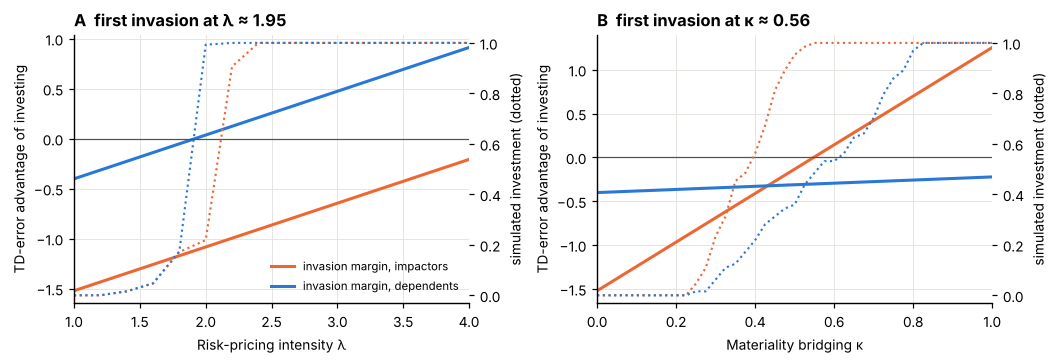

In [7]:
R = np.load(HERE / 'results.npz')
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.2), constrained_layout=True)
for ax, (lev, grid, lab) in zip(axs, [('lam', np.linspace(1, 4, 61), 'Risk-pricing intensity λ'),
                                      ('kappa', np.linspace(0, 1, 51), 'Materiality bridging κ')]):
    m = [stability_margins(two_group_env(0.8, **{lev: v})) for v in grid]
    inv = np.array([x['invasion'] for x in m])
    ax.plot(grid, inv[:, 0], color=S2, lw=2, label='invasion margin, impactors')
    ax.plot(grid, inv[:, 2], color=S1, lw=2, label='invasion margin, dependents')
    ax.axhline(0, color=INK2, lw=.8)
    ax2 = ax.twinx(); ax2.spines['top'].set_visible(False)
    v = R[f'E2_{lev}_vals']; ax2.plot(v, R[f'E2_{lev}_imp'], color=S2, ls=':', lw=1.4)
    ax2.plot(v, R[f'E2_{lev}_dep'], color=S1, ls=':', lw=1.4); ax2.set_ylim(-.03, 1.03)
    ax2.set_ylabel('simulated investment (dotted)'); ax.set_xlabel(lab); ax.set_ylabel('TD-error advantage of investing')
    ax.grid(color=GRID, lw=.6); ax.set_xlim(grid[0], grid[-1])
    zc = grid[np.argmax((inv > 0).any(1))] if (inv > 0).any() else np.nan
    ax.set_title(f'{"AB"[lev == "kappa"]}  first invasion at {lab.split()[-1]} ≈ {zc:.2f}')
axs[0].legend(fontsize=7.5, loc='lower right')
plt.show()

The margins reproduce the simulated thresholds at no simulation cost. The zero crossing marks where the non-investment trap disappears, so that investment is reached from *every* starting point; the partial rise before it comes from starting points already inside the cooperative basin. Under risk loading the **dependents** move first (crossing at λ ≈ 1.95, where the simulated transition completes). Under bridging the **impactors** move first (κ ≈ 0.56, where all simulated impactors invest).

**Applied use.** With a calibrated basin, compute the margins firm by firm. The firm whose invasion margin is closest to zero is the cheapest to move first, and the size of its gap is the minimum instrument strength. Tracking how the margins change as disclosure rules, contract terms or capital requirements change gives a supervisor-facing early-warning indicator that needs no learning simulation.

In [8]:
m = stability_margins(NatureCommons(**BASIN))
pd.DataFrame({'firm': names, 'invasion margin (nobody invests)': m['invasion'].round(2),
              'defection margin (everybody invests)': m['defection'].round(2)}).set_index('firm')

,invasion margin (nobody invests),defection margin (everybody invests)
firm,,
Irrigated sugar estate,-1.06,-9.03
Hydropower operator,-0.32,-1.24
Beverage bottler,-0.32,-2.89
Forestry plantation,-1.30,-0.50
Agri-trader (outgrowers),-0.95,0.20


In the illustrative basin, every invasion margin is negative, so the trap is stable. The downstream firms (hydropower, bottler) are closest to moving first. One firm, the agri-trader, has a **positive defection margin**: even if all others invest, it gains by not investing. Here collective investment is not an equilibrium at all, so the problem is incentives as well as selection, and that firm needs an instrument of its own (for example, outgrower contracts with sourcing conditions).

## 5  Payment design

The manuscript shows that water-fund-style **buy-outs** convert impactors but crowd out dependents' own action. Is that a property of payments, or of this design? We compare three budget-balanced designs, each paid while the ecosystem stays prosperous:

| design | who pays | who receives |
|---|---|---|
| buy-out | dependents | investing impactors |
| levy-and-rebate | every firm, an equal levy | every investing firm |
| pressure fee | non-investing firms, in proportion to their pressure $h_i$ | all firms, equal recycling |

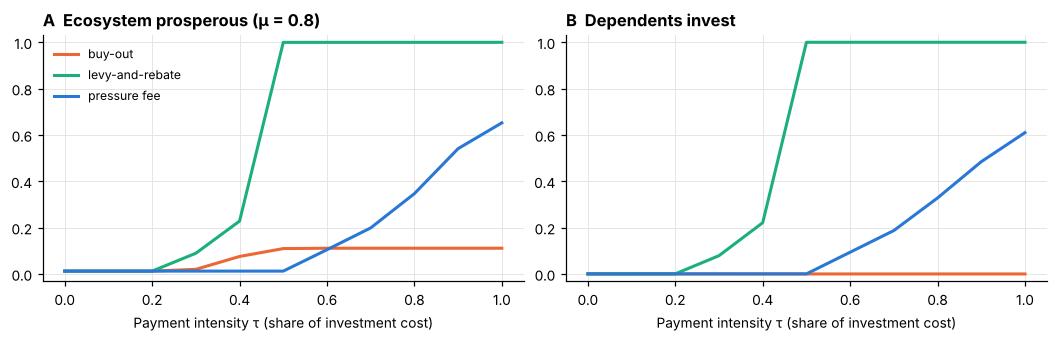

τ,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
buy-out,0.01,0.01,0.01,0.02,0.08,0.11,0.11,0.11,0.11,0.11,0.11
levy-and-rebate,0.01,0.01,0.01,0.09,0.23,1.00,1.00,1.00,1.00,1.00,1.00
pressure fee,0.01,0.01,0.01,0.01,0.01,0.01,0.10,0.20,0.35,0.54,0.65


In [9]:
taus = np.round(np.linspace(0, 1, 11), 2)
designs = {'buy-out': 'buyout', 'levy-and-rebate': 'rebate', 'pressure fee': 'fee'}
pay = {k: [evaluate(two_group_env(0.8, cls=TransferNC, design=v, tau_d=t), X0) for t in taus] for k, v in designs.items()}
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.0), constrained_layout=True)
for (k, rs), col in zip(pay.items(), [S2, S3, S1]):
    axs[0].plot(taus, [r['prosp'] for r in rs], color=col, lw=2, label=k)
    axs[1].plot(taus, [r['invest'][2:].mean() for r in rs], color=col, lw=2, label=k)
axs[0].set_title('A  Ecosystem prosperous (μ = 0.8)'); axs[1].set_title('B  Dependents invest')
for ax in axs:
    ax.set_xlabel('Payment intensity τ (share of investment cost)'); ax.grid(color=GRID, lw=.6); ax.set_ylim(-.03, 1.03)
axs[0].legend(fontsize=8)
plt.show()
pd.DataFrame({k: [r['prosp'] for r in rs] for k, rs in pay.items()}, index=taus).rename_axis('τ').T.round(2)

Crowding-out is a design property, not a property of payments. A **levy-and-rebate** that rewards *any* investing firm reaches full prosperity from τ = 0.5, because dependents keep an incentive to invest; the buy-out stays at 0.11. A pressure fee helps but reaches only about 0.65 even at τ = 1. For water funds this suggests rewarding every member's own basin action, not routing dependents' money to impactors in place of their own action. This tests the transfer-variant caveat in the manuscript's pre-submission notes.

## 6  Robustness: number of firms and ecosystem fragility

The manuscript uses four firms and collapse leverage $q_c = 0.8$. Here we vary both (half the firms are impactors, half dependents, as in the manuscript).

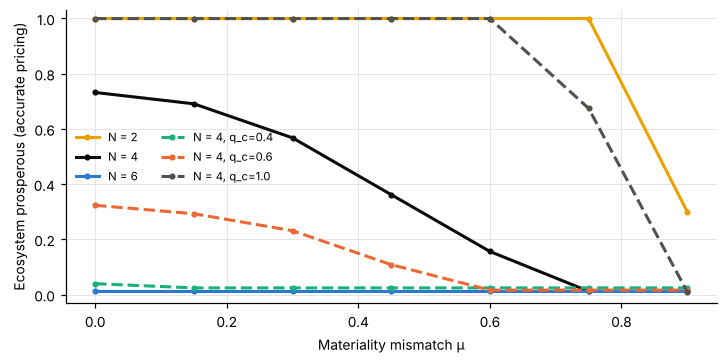

mu,0.00,0.15,0.30,0.45,0.60,0.75,0.90
N,,,,,,,
2,1.00,1.00,1.00,1.00,1.00,1.00,0.30
4,0.73,0.69,0.57,0.36,0.16,0.01,0.01
6,0.01,0.01,0.01,0.01,0.01,0.01,0.01
"4, q_c=0.4",0.04,0.02,0.02,0.02,0.02,0.02,0.02
"4, q_c=0.6",0.32,0.29,0.23,0.11,0.02,0.02,0.02
"4, q_c=1.0",1.00,1.00,1.00,1.00,1.00,0.67,0.01


In [10]:
mus = np.round(np.arange(0, 0.91, 0.15), 2)
rows = []
for N in [2, 4, 6]:
    X0N = random_inits(48, N, seed=2)
    for mu_ in mus:
        rows.append(dict(N=N, mu=mu_, prosp=evaluate(two_group_env(mu_, N=N), X0N)['prosp']))
for qc in [0.4, 0.6, 1.0]:
    for mu_ in mus:
        rows.append(dict(N=f'4, q_c={qc}', mu=mu_, prosp=evaluate(two_group_env(mu_, N=4, qc=qc), X0)['prosp']))
rob = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 3.2), constrained_layout=True)
for (k, g), col, ls in zip(rob.groupby('N', sort=False), [S4, INK, S1, S3, S2, INK2], ['-', '-', '-', '--', '--', '--']):
    ax.plot(g['mu'], g['prosp'], color=col, ls=ls, lw=2, marker='o', ms=3, label=f'N = {k}' if 'q_c' not in str(k) else f'N = {k}')
ax.set_xlabel('Materiality mismatch μ'); ax.set_ylabel('Ecosystem prosperous (accurate pricing)')
ax.grid(color=GRID, lw=.6); ax.legend(fontsize=7.5, ncol=2); ax.set_ylim(-.03, 1.03)
plt.show()
rob.pivot(index='N', columns='mu', values='prosp').round(2)

Accurate pricing fails at μ = 0.9 in every setting (prosperity at most 0.30). The threshold, however, depends strongly on group size and fragility:
* two firms tolerate mismatch up to μ = 0.75;
* six firms fail even with no mismatch, the large-collective problem of ref. 5;
* a less fragile ecosystem ($q_c$ = 0.4) removes cooperation altogether, because the deterrent of collapse is weaker, while $q_c$ = 1.0 sustains it up to μ ≈ 0.6.

Two implications. The qualitative result, that risk pricing fails under high mismatch, is robust. But the four-firm thresholds are not general, so N and $q_c$ must be calibrated per basin (§2, §8), and basins with many firms may need instruments even where impacts and dependencies are aligned.

## 7  Robustness: sampled learners and learning time scales

The deterministic dynamics are the limit of independent actor-critic learners that update their *strategy* slowly relative to their *value estimates*. Here firms actually play the stochastic game: they sample actions, observe noisy rewards and rare collapses, and update a tabular critic (rate ζ) and softmax policy (rate η).
We compare a slow-strategy regime (η = 0.002) with a fast-strategy regime (η = 0.01), both with ζ = 0.05.

,deterministic,"sampled, η=0.002","sampled, η=0.01"
case,,,
"μ=0, accurate pricing",0.75,0.92,1.00
"μ=0.8, accurate pricing",0.01,0.01,0.01
"μ=0.8, bridging κ=0.9",1.00,0.89,0.45
"μ=0.8, levy-and-rebate τ=0.6",1.00,0.87,0.70


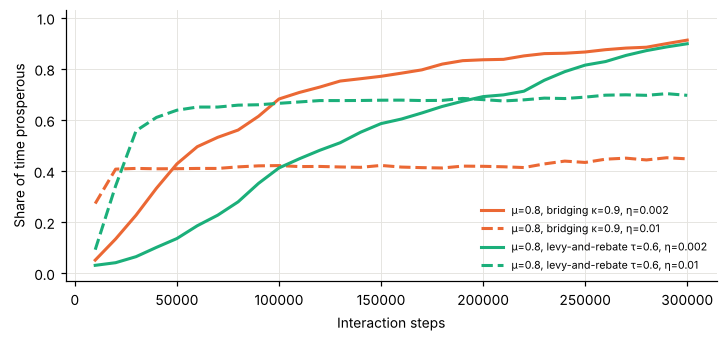

In [11]:
cases = [('μ=0, accurate pricing', dict(mu=0.0)), ('μ=0.8, accurate pricing', dict(mu=0.8)),
         ('μ=0.8, bridging κ=0.9', dict(mu=0.8, kappa=0.9)),
         ('μ=0.8, levy-and-rebate τ=0.6', dict(mu=0.8, cls=TransferNC, design='rebate', tau_d=0.6))]
rows, curves = [], {}
for lab, kw in cases:
    env = two_group_env(**kw)
    det = evaluate(env, X0)
    row = dict(case=lab, deterministic=det['prosp'])
    for eta in [0.002, 0.01]:
        hp, hs = StochasticAC(env, gamma=0.9, eta=eta, zeta=0.05, seed=1).run(B=48, T=300_000, record_every=10_000)
        row[f'sampled, η={eta}'] = hs[-5:].mean()
        curves[(lab, eta)] = hs.mean(1)
    rows.append(row)
display(pd.DataFrame(rows).set_index('case').round(2))
fig, ax = plt.subplots(figsize=(6.5, 3.0), constrained_layout=True)
for (lab, eta), y in curves.items():
    if 'κ=0.9' in lab or 'rebate' in lab:
        ax.plot(np.arange(1, len(y) + 1) * 10_000, y, lw=2, ls='-' if eta == 0.002 else '--',
                color=S2 if 'κ' in lab else S3, label=f'{lab}, η={eta}')
ax.set_xlabel('Interaction steps'); ax.set_ylabel('Share of time prosperous'); ax.grid(color=GRID, lw=.6)
ax.legend(fontsize=7); ax.set_ylim(-.03, 1.03); plt.show()

When firms revise strategy slowly relative to how fast they learn values, sampled learners approach the deterministic prediction: 0.87–0.89 at 300,000 steps against 1.00, and still rising. When they revise quickly on noisy feedback, dependents often lock into not investing (0.45–0.70), because collapse signals are rare and their own advantage of investing is small (see §4). Without mismatch, sampling noise *helps* (0.92–1.00 against 0.75), as in ref. 13 of the manuscript. Two implications:
* **For the paper:** the deterministic results are an upper bound for fast-reacting firms, so report this time-scale condition (Box 1, Q7).
* **For policy:** instruments that reduce feedback noise help coordination. Examples are basin monitoring, multi-year KPIs instead of annual ones, and pooled loss data.

## 8  Empirical pipeline template

The test the manuscript needs (Box 1, Q16): **does the model's predicted prosperity for a basin predict observed corporate co-investment there, out of sample?**

### Input schema (one row per firm × basin)

| column | meaning | candidate sources |
|---|---|---|
| `basin_id` | HydroBASINS level-6 to 8 identifier | HydroBASINS |
| `firm_id`, `sector` | identifiers | Compustat / Orbis / Bloomberg |
| `pressure` | firm's pressure on the basin | CDP Water withdrawals; ENCORE pressure × production; land-conversion layers |
| `revenue_at_risk` | loss if the basin degrades | Compustat segments (WRDS), Bloomberg; ENCORE dependency × revenue; asset-location data |
| `bridge_share` | share of the firm's basin exposure linked to other basin firms through contracts or lenders (κ proxy) | FactSet Revere / Bloomberg SPLC; LSEG Deals sustainability-linked loans |
| `coinvest` (basin level) | basin hosts a corporate co-investment platform (water fund, landscape programme) | Water Action Hub, water-fund registries, CDP engagement responses |

The cell below **generates a synthetic panel** of 150 basins with this schema, so the code runs. The outcome is simulated from the model prediction, so the model *should* win. The point is the mechanics, plus a power calculation for how many basins the real test needs.

In [12]:
rng = np.random.default_rng(42)
recs, outcome = [], {}
for b in range(150):
    n = rng.integers(3, 6)
    corr = rng.uniform(-0.8, 0.8)                       # alignment of pressure and exposure in this basin
    z = rng.standard_normal((n, 2)); z[:, 1] = corr * z[:, 0] + np.sqrt(1 - corr ** 2) * z[:, 1]
    for k in range(n):
        recs.append(dict(basin_id=f'B{b:03d}', firm_id=f'B{b:03d}-F{k}', sector=rng.choice(['agri', 'forestry', 'mining', 'beverages', 'utilities']),
                         pressure=np.exp(1 + z[k, 0]), revenue_at_risk=np.exp(1 + z[k, 1]), bridge_share=rng.uniform(0, 0.6)))
panel = pd.DataFrame(recs)
display(panel.head())

def predict_basin(g, X0s={}):
    h, d, mu, used = basin_from_firms(g, max_firms=5)
    kv = used['bridge_share'].to_numpy()
    N = len(h); X0s.setdefault(N, random_inits(24, N, seed=2))
    r = evaluate(TargetedNC(h=h, dep=d, qc=0.8, kappa_vec=kv), X0s[N])
    return pd.Series(dict(n_firms=N, mu=mu, mean_bridge=kv.mean(), predicted_prosperity=r['prosp']))

t = time.time()
basins = panel.groupby('basin_id').apply(predict_basin)
print(f'{len(basins)} basins calibrated and simulated in {time.time() - t:.0f}s')
# synthetic outcome (for demonstration only)
lin = -2 + 4 * basins['predicted_prosperity']
basins['coinvest'] = (rng.random(len(basins)) < 1 / (1 + np.exp(-lin))).astype(int)
basins.round(2).head()

,basin_id,firm_id,sector,pressure,revenue_at_risk,bridge_share
0,B000,B000-F0,beverages,5.757200,6.440887,0.076868
1,B000,B000-F1,utilities,0.386341,0.900201,0.222479
2,B000,B000-F2,mining,3.088978,1.959660,0.556059
3,B001,B001-F0,beverages,4.338416,1.657959,0.467030
4,B001,B001-F1,beverages,3.930438,1.446727,0.280033


150 basins calibrated and simulated in 71s


,n_firms,mu,mean_bridge,predicted_prosperity,coinvest
basin_id,,,,,
B000,3.0,0.12,0.29,0.23,0
B001,5.0,0.08,0.33,0.03,0
B002,4.0,0.40,0.35,0.67,1
B003,5.0,0.33,0.32,0.09,0
B004,4.0,0.48,0.36,0.13,1


In [13]:
def auc(score, y):
    score, y = np.asarray(score), np.asarray(y)
    pos, neg = score[y == 1], score[y == 0]
    return ((pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean())

def logit_fit(X, y):
    X = np.column_stack([np.ones(len(X)), X])
    nll = lambda b: np.sum(np.logaddexp(0, X @ b) - y * (X @ b))
    res = minimize(nll, np.zeros(X.shape[1]), method='BFGS')
    se = np.sqrt(np.diag(res.hess_inv))
    return res.x, se

basins['total_exposure'] = panel.groupby('basin_id')['revenue_at_risk'].sum()
# Each score is used with its sign fixed in advance, so no parameters are fitted and the AUC is out of sample.
scores = {'model: predicted prosperity (+)': basins['predicted_prosperity'],
          'mismatch μ (−)': -basins['mu'],
          'benchmark: total exposure (+, risk-pricing logic)': basins['total_exposure']}
display(pd.Series({k: auc(v, basins['coinvest']) for k, v in scores.items()},
                  name='AUC, sign fixed in advance (synthetic data)').round(2).to_frame())
cols = ['predicted_prosperity', 'mu', 'total_exposure', 'n_firms']
Z = ((basins[cols] - basins[cols].mean()) / basins[cols].std()).to_numpy()
b, se = logit_fit(Z, basins['coinvest'].to_numpy())
pd.DataFrame({'coef': b, 'se': se, 'z': b / se}, index=['const'] + [c + ' (std)' for c in cols]).round(2)

,"AUC, sign fixed in advance (synthetic data)"
model: predicted prosperity (+),0.81
mismatch μ (−),0.52
"benchmark: total exposure (+, risk-pricing logic)",0.37


,coef,se,z
const,-0.47,0.21,-2.29
predicted_prosperity (std),1.47,0.29,5.08
mu (std),0.05,0.22,0.22
total_exposure (std),-0.06,0.24,-0.25
n_firms (std),0.07,0.29,0.24


**Power.** How many basins are needed to detect the model's predictive effect? We resample basins from the synthetic panel and redraw outcomes from the same process. Power is the share of resamples in which the coefficient on predicted prosperity is positive at p < 0.05, controlling for exposure, mismatch and the number of firms. Under a weaker true effect, power falls quickly, so run this with your own effect-size assumptions before collecting data.

In [14]:
from scipy.stats import norm
p_true = basins['predicted_prosperity'].to_numpy()
rows = []
for slope in [2, 4]:
    for n in [30, 60, 100, 150]:
        hits = 0
        for rep_ in range(200):
            idx = rng.choice(len(basins), n, replace=True)
            y = (rng.random(n) < 1 / (1 + np.exp(-(-slope / 2 + slope * p_true[idx])))).astype(int)
            Zs = Z[idx]
            try:
                bb, ss = logit_fit(Zs, y)
                hits += (bb[1] / ss[1] > norm.ppf(0.975))
            except Exception:
                pass
        rows.append(dict(effect=f'logit slope {slope}', basins=n, power=hits / 200))
pd.DataFrame(rows).pivot(index='effect', columns='basins', values='power')

basins,30,60,100,150
effect,,,,
logit slope 2,0.310,0.55,0.795,0.925
logit slope 4,0.535,0.98,1.000,1.000


**With real data**, replace the synthetic block with `panel = pd.read_csv('your_firm_basin_panel.csv')`, keep `predict_basin`, and replace the synthetic `coinvest` with observed outcomes. The key comparison is the model against the *risk-pricing benchmark* (exposure alone): that is the manuscript's claim in testable form. Extensions:
* staggered difference-in-differences around disclosure mandates (Box 1, Q17);
* persistence of co-investment after programme funding ends (Q18);
* clustering standard errors by country or major basin.

## 9  Suggested improvements to pyCRLD for applied corporate decision analysis

pyCRLD is a clean research library for the dynamics of collective learning. Applied decision analysis, with many heterogeneous firms, policy instruments, calibration to data and decision-ready outputs, needs more. The suggestions are ordered by priority. Each cites the evidence from this project and, where one exists, a working prototype in this folder.

| # | Priority | Issue found in this project | Suggested change | Prototype here |
|---|---|---|---|---|
| 1 | **P0 correctness** | `_OtherAgentsActionsSummationTensor` sums every ordering of the other agents: rows of `Tisas` sum to (N−1)!, and results for N ≥ 3 are wrong (§1) | Keep one canonical ordering; add regression tests: `Tisas` rows sum to 1, `Risa` equals a constant reward, brute-force comparison for N = 3, 4 | `pycrld_bridge.corrected_Omega`, `pyCRLD_issue_draft.md` |
| 2 | **P0 packaging** | `pip install -e` fails on current setuptools: `setup.py` imports the removed `pkg_resources` | Use `packaging.version` or move to `pyproject.toml`; pin a tested jax range; publish to PyPI | — |
| 3 | **P0 numerics** | Default float32 freezes slow strategy drift near basin boundaries (κ = 0.5 scaffold: 0.38 vs 0.32); large TD errors overflow `exp` and give NaN | Expose a precision flag defaulting to float64 for research runs; update in log-space (logits) with log-sum-exp normalisation; warn on NaN or non-convergence | `CRLD_X64` switch in `pycrld_bridge.py` |
| 4 | P1 scale | Dense `Omega` has N^N·M^(2N) entries (65,536 for N = 4; 1.9 × 10⁸ for N = 6), so basins with many firms are out of reach | Contract the other agents' marginals one by one (product of marginals), with no permutation tensor; add **agent types** (classes of identical firms) to model sectors with many firms | `crld.CRLD` uses per-agent marginals and runs N = 6 in about 1 s |
| 5 | P1 batching | `trajectory` runs one initial condition at a time in a Python loop | `vmap` over initial conditions **and** parameter grids, with a jitted convergence loop (`lax.while_loop`); built-in `basin_of_attraction()` | `pycrld_bridge.PyCRLD.run` (vmap + `fori_loop`) |
| 6 | P1 applied environment | `EcologicalPublicGood` has per-agent `qc`, `m`, but impact shares, dependency and costs are implicit; firms are anonymous | A `SharedEcosystem` environment with named firms, impact shares, dependency, per-firm costs and recovery, multi-level degradation states and coupled sub-basins (network of ecosystems) | `crld.NatureCommons`, `analysis_lib.basin_from_firms` |
| 7 | P1 policy layer | Instruments are hard-coded into reward tensors | Composable **instrument objects** that transform R and T: risk loading, (targeted) other-regarding rewards, payment designs, fees, caps; **time-varying schedules** for scaffolds, phase-ins and withdrawal | `TargetedNC`, `TransferNC`; scaffold loops in `experiments2.py` |
| 8 | P1 information | Agents learn on the true environment; no notion of mis-measured risk | Agent-specific *perceived* environments distinct from the true dynamics; generators for independent, correlated (monoculture) and pooled assessment errors; outcomes always scored on the true environment | E5 in `experiments.py` |
| 9 | P2 diagnostics | Stability analysis requires heavy simulation | Invasion and defection margins, Jacobian spectra at fixed points, separatrix via `reverse_step` (exists), critical slowing down, parameter continuation for hysteresis | `analysis_lib.stability_margins` (§4) |
| 10 | P2 stochastic counterpart | Deterministic limit can overstate coordination when firms update fast (§7) | A sample-based learner on the same environment API with explicit actor and critic time scales, to bound deterministic results | `analysis_lib.StochasticAC` |
| 11 | P2 decision outputs | Outputs are strategies and values in model units | Helpers for stationary prosperity, expected losses in currency, instrument cost per unit of prosperity gained, minimum-intensity “price tags”, firm-targeting rankings | §2, §3 |
| 12 | P2 calibration | No data interface | Constructors from firm–basin tables; Monte Carlo propagation of parameter uncertainty; units and documentation of parameter semantics (for example that per-agent `qc` is divided by N) | `basin_from_firms`, §8 |

The last cell times the batching suggestion (item 5) on this machine.

In [15]:
if HAVE_PYCRLD:
    from experiments import make_env
    nc = make_env(0.8, kappa=0.6); Tm = 2000
    agent = stratAC_fixed(env=pycrld_env(nc), learning_rates=0.05, discount_factors=0.9)
    agent.trajectory(jnp.asarray(X0[0]), Tmax=10)                       # compile
    t = time.time()
    for x in X0[:4]:
        agent.trajectory(jnp.asarray(x), Tmax=Tm, tolerance=None)
    loop_per_traj = (time.time() - t) / 4
    eng = PyCRLD(nc, alpha=0.05, gamma=0.9); eng.run(X0, Tmax=100, tol=0)  # compile
    t = time.time(); eng.run(X0, Tmax=Tm, tol=0.0); batched = time.time() - t
    print(f'stock trajectory loop: {loop_per_traj * 64:.1f}s for 64 trajectories x {Tm} steps (extrapolated from 4)')
    print(f'vmapped + jitted loop: {batched:.1f}s for the same work  ->  {loop_per_traj * 64 / batched:.0f}x faster')
print(f'notebook total runtime: {(time.time() - T_START) / 60:.1f} min')

stock trajectory loop: 12.4s for 64 trajectories x 2000 steps (extrapolated from 4)
vmapped + jitted loop: 0.9s for the same work  ->  13x faster
notebook total runtime: 9.7 min
